<a href="https://colab.research.google.com/github/gayathridevies-arch/Soil-Geochemistry-Depth-Profile-Analysis/blob/main/Soil_Geochemistry_Depth_Profile_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

,Sample_ID,Location,Depth_Horizon,pH,Organic_Carbon_%,CEC_meq100g
0,Site_01_0-15 cm,Site_01,0-15 cm,5.95,3.84,29.7
1,Site_01_15-30 cm,Site_01,15-30 cm,6.86,2.03,13.9
2,Site_01_30-50 cm,Site_01,30-50 cm,6.47,1.06,6.4
3,Site_02_0-15 cm,Site_02,0-15 cm,6.26,3.67,28.2
4,Site_02_15-30 cm,Site_02,15-30 cm,6.55,2.48,18.2
5,Site_02_30-50 cm,Site_02,30-50 cm,7.21,1.06,9.0
6,Site_03_0-15 cm,Site_03,0-15 cm,6.27,3.92,30.1
7,Site_03_15-30 cm,Site_03,15-30 cm,5.71,2.13,15.9
8,Site_03_30-50 cm,Site_03,30-50 cm,6.91,0.96,5.9
9,Site_04_0-15 cm,Site_04,0-15 cm,5.96,3.71,25.5


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Sample_ID         30 non-null     object 
 1   Location          30 non-null     object 
 2   Depth_Horizon     30 non-null     object 
 3   pH                30 non-null     float64
 4   Organic_Carbon_%  30 non-null     float64
 5   CEC_meq100g       30 non-null     float64
dtypes: float64(3), object(3)
memory usage: 1.5+ KB


None

File Saved


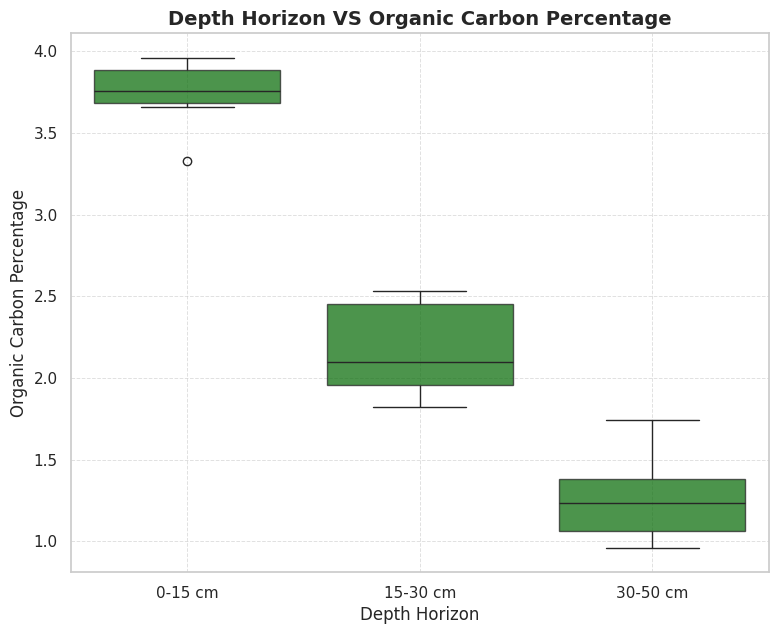

pH                       Organic_Carbon_%                  \
                mean       std   max   min             mean       std   max   
Depth_Horizon                                                                 
0-15 cm        5.875  0.252466  6.27  5.53            3.750  0.182148  3.96   
15-30 cm       6.286  0.366309  6.86  5.71            2.172  0.280785  2.53   
30-50 cm       6.796  0.373964  7.26  6.01            1.264  0.256220  1.74   

                    CEC_meq100g                        
                min        mean       std   max   min  
Depth_Horizon                                          
0-15 cm        3.33       28.20  1.868452  30.3  25.5  
15-30 cm       1.82       15.66  2.197069  19.2  12.8  
30-50 cm       0.96       10.36  3.656410  18.9   5.9

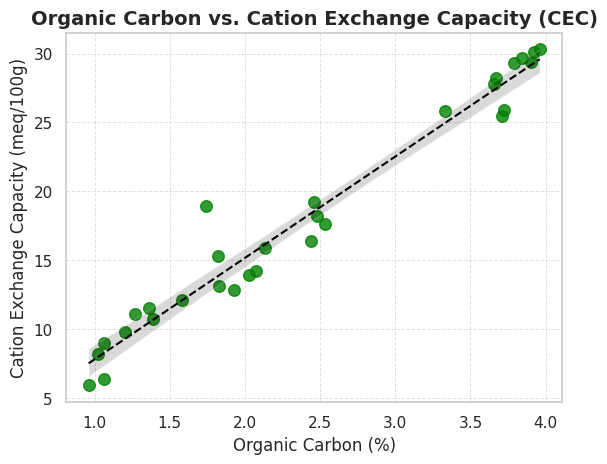

Summary statistics successfully exported to 'soil_geochemistry_summary_stats.csv'!


In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
np.random.seed(42)
sites=[f"Site_{i+1:02d}" for i in range(10)]
depths = ["0-15 cm", "15-30 cm", "30-50 cm"]
data_rows=[]
for site in sites:
  for depth in depths:
    data_rows.append({"Location": site, "Depth_Horizon": depth})
df_soil=pd.DataFrame(data_rows)
df_soil["Sample_ID"]=df_soil["Location"]+"_"+df_soil["Depth_Horizon"].str.replace("","")
n=len(df_soil)
pH=np.where(df_soil["Depth_Horizon"]=="0-15 cm",np.random.normal(5.8, 0.3, n),#First condition and Value if True (Surface)
            np.where(df_soil["Depth_Horizon"]=="15-30 cm",# Value if False (Opens the inner gate) and inner condition
            np.random.normal(6.3,0.3,n),np.random.normal(6.8,0.3,n),),)# Inner Value if True (Mid) and # inner value if false
OC= np.where(df_soil["Depth_Horizon"] == "0-15 cm",np.random.normal(3.8, 0.4, n),
    np.where(df_soil["Depth_Horizon"] == "15-30 cm",np.random.normal(2.3, 0.3, n),
        np.random.normal(1.2, 0.2, n),),)
CEC = OC * 7.5 + np.random.normal(0, 1.5, n)
df_soil["pH"] = np.round(pH, 2)
df_soil["Organic_Carbon_%"] = np.round(OC, 2)
df_soil["CEC_meq100g"] = np.round(CEC, 1)
#reordering the table for easiness
df_soil= df_soil[
    ["Sample_ID", "Location", "Depth_Horizon", "pH", "Organic_Carbon_%", "CEC_meq100g"]
]
display(df_soil.head(10))
display(df_soil.info())
df_soil.to_csv("soil_geochemistry_data.csv")
print("File Saved")
sns.set_theme(style="whitegrid")
plt.figure(figsize=(9,7))
sns.boxplot(data=df_soil,x="Depth_Horizon",y="Organic_Carbon_%",color="green",boxprops=dict(alpha=0.75))# In newer versions of Seaborn, passing a single color name (like "palette='green'") to a categorical plot triggers a warning or error. Instead, Seaborn prefers using color="green" for single-color plots.
plt.grid(linestyle="--", linewidth=0.7, alpha=0.6)
plt.title("Depth Horizon VS Organic Carbon Percentage",fontsize=14,fontweight="bold")
plt.xlabel("Depth Horizon",fontsize=12)
plt.ylabel("Organic Carbon Percentage",fontsize=12)
plt.show()
display(df_soil.groupby("Depth_Horizon")[["pH","Organic_Carbon_%","CEC_meq100g"]].agg(["mean","std","max","min"]))#Aggregate (agg): It calculates the mean (average) and standard deviation (std, how spread out the numbers are) for each of those three piles independently.
sns.regplot(data=df_soil,x="Organic_Carbon_%",y="CEC_meq100g",color="green",scatter_kws={"alpha": 0.8,"s": 70,},  # Adjust dot transparency and size for clarity
    line_kws={"color": "black", "linestyle": "--", "linewidth": 1.5})
plt.title( "Organic Carbon vs. Cation Exchange Capacity (CEC)",fontsize=14,fontweight="bold")
plt.xlabel("Organic Carbon (%)", fontsize=12)
plt.ylabel("Cation Exchange Capacity (meq/100g)", fontsize=12)
plt.grid(linestyle="--", linewidth=0.7, alpha=0.6)
plt.show()
summary_stats = (df_soil.groupby("Depth_Horizon")[["pH", "Organic_Carbon_%", "CEC_meq100g"]].agg(["mean", "std"]).round(2))
summary_stats.to_csv("soil_geochemistry_summary_stats.csv")
print("Summary statistics successfully exported to 'soil_geochemistry_summary_stats.csv'!")